# GLP-1 Medicaid Drug Utilization — Data Checks and Visualizations

This notebook follows the 17 steps in the supplied code and adds exploratory graphs. **Important:** The drug list is preliminary, suppressed counts are unknown, and raw prescription totals are not enrollment-adjusted utilization rates.

## Step 1 — Load The Dataset

In [31]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\kathy\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [32]:
import pandas as pd
from pathlib import Path

# STEP 1 — LOAD THE DATASET

file_path = "data.csv"

if not Path(file_path).exists():
    raise FileNotFoundError(
        f"Place {file_path} beside this notebook, or update file_path."
    )

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print(f"Total rows: {len(df):,}")
print(f"Total columns: {len(df.columns)}")





# ------------------------------------------------------------

Dataset loaded successfully!
Total rows: 5,308,547
Total columns: 15


## Step 2 — Clean Column Names

In [33]:
# ------------------------------------------------------------



df.columns = df.columns.str.strip()



print("\nColumns:")

for col in df.columns:

    print(repr(col))





# ------------------------------------------------------------


Columns:
'Utilization Type'
'State'
'NDC'
'Labeler Code'
'Product Code'
'Package Size'
'Year'
'Quarter'
'Suppression Used'
'Product Name'
'Units Reimbursed'
'Number of Prescriptions'
'Total Amount Reimbursed'
'Medicaid Amount Reimbursed'
'Non Medicaid Amount Reimbursed'


## Step 3 — Standardize Column Names

In [34]:
# ------------------------------------------------------------



column_lookup = {

    col.lower().strip(): col

    for col in df.columns

}





def find_column(possible_names):

    for name in possible_names:

        key = name.lower().strip()



        if key in column_lookup:

            return column_lookup[key]



    return None





state_col = find_column([

    "State",

    "state"

])



product_col = find_column([

    "Product Name",

    "product_name",

    "product name"

])



year_col = find_column([

    "Year",

    "year"

])



quarter_col = find_column([

    "Quarter",

    "quarter"

])



prescription_col = find_column([

    "Number of Prescriptions",

    "number_of_prescriptions",

    "number of prescriptions"

])



suppression_col = find_column([

    "Suppression Used",

    "suppression_used",

    "suppression used"

])





# ------------------------------------------------------------

## Step 4 — Check Required Columns

In [35]:
# ------------------------------------------------------------



print("\nDetected columns:")



print("State:", state_col)

print("Product Name:", product_col)

print("Year:", year_col)

print("Quarter:", quarter_col)

print("Number of Prescriptions:", prescription_col)

print("Suppression Used:", suppression_col)





required_columns = {

    "State": state_col,

    "Product Name": product_col,

    "Quarter": quarter_col,

    "Number of Prescriptions": prescription_col,

    "Suppression Used": suppression_col

}



missing_columns = [

    name

    for name, col in required_columns.items()

    if col is None

]



if missing_columns:

    raise ValueError(

        "\nCould not find these required columns:\n"

        + ", ".join(missing_columns)

        + "\n\nLook at the column list printed above."

    )





# ------------------------------------------------------------


Detected columns:
State: State
Product Name: Product Name
Year: Year
Quarter: Quarter
Number of Prescriptions: Number of Prescriptions
Suppression Used: Suppression Used


## Step 5 — Check State Coverage

In [36]:
# ------------------------------------------------------------



states = sorted(

    df[state_col]

    .dropna()

    .astype(str)

    .str.strip()

    .unique()

)



print("\n================ STATE COVERAGE ================")



print("State/Jurisdiction Codes:")

print(states)



print("\nNumber of State/Jurisdiction Codes:")

print(len(states))





# ------------------------------------------------------------


================ STATE COVERAGE ================
State/Jurisdiction Codes:
['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'PR', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV', 'WY', 'XX']

Number of State/Jurisdiction Codes:
53


## Step 6 — Standardize Product Names

In [37]:
# ------------------------------------------------------------



df[product_col] = (

    df[product_col]

    .astype(str)

    .str.strip()

    .str.upper()

)





# ------------------------------------------------------------

## Step 7 — Preliminary Glp-1 List

In [38]:
# ------------------------------------------------------------

# IMPORTANT:

# These drugs came from the preliminary exploration.

# We still need to verify the full GLP-1 drug list.



glp1_drugs = [

    "TRULICITY",

    "MOUNJARO",

    "ZEPBOUND"

]



glp1_data = df[

    df[product_col].isin(glp1_drugs)

].copy()





print("\n================ GLP-1 CHECK ================")



print("GLP-1 drugs currently included:")

print(

    sorted(

        glp1_data[product_col]

        .dropna()

        .unique()

    )

)



print("\nTotal GLP-1 records:")

print(f"{len(glp1_data):,}")





# ------------------------------------------------------------


================ GLP-1 CHECK ================
GLP-1 drugs currently included:
['MOUNJARO', 'TRULICITY', 'ZEPBOUND']

Total GLP-1 records:
3,946


## Step 8 — Check Quarter Coverage

In [39]:
# ------------------------------------------------------------



quarters = sorted(

    glp1_data[quarter_col]

    .dropna()

    .unique()

)



print("\n================ QUARTER COVERAGE ================")



print("Quarters found:")

print(quarters)





# ------------------------------------------------------------


================ QUARTER COVERAGE ================
Quarters found:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## Step 9 — Check State × Quarter Data Coverage

In [40]:
# ------------------------------------------------------------

# This table counts RECORDS, not prescriptions.

# It is only used to check whether each state has data

# in each quarter.



state_quarter_records = pd.crosstab(

    glp1_data[state_col],

    glp1_data[quarter_col]

)





missing_quarter_states = state_quarter_records[

    (state_quarter_records == 0).any(axis=1)

]





print("\n================ STATE × QUARTER COVERAGE ================")



print(

    "States/jurisdictions with incomplete quarter coverage:",

    len(missing_quarter_states)

)



if len(missing_quarter_states) > 0:

    print(missing_quarter_states)

else:

    print("All states/jurisdictions have GLP-1 records in every quarter.")





# ------------------------------------------------------------


================ STATE × QUARTER COVERAGE ================
States/jurisdictions with incomplete quarter coverage: 0
All states/jurisdictions have GLP-1 records in every quarter.


**Coverage note:** This checks quarters that appear in the filtered records; it does not guarantee all four quarters exist.

In [41]:
expected_quarters = [1, 2, 3, 4]
coverage = state_quarter_records.reindex(columns=expected_quarters, fill_value=0)
print("States missing at least one of Q1–Q4:", (coverage.eq(0).any(axis=1)).sum())

States missing at least one of Q1–Q4: 0


## Step 10 — Standardize Suppression Used

In [42]:
# ------------------------------------------------------------



glp1_data[suppression_col] = (

    glp1_data[suppression_col]

    .astype(str)

    .str.strip()

    .str.upper()

)





print("\n================ SUPPRESSION VALUES ================")



print(

    glp1_data[suppression_col]

    .value_counts(dropna=False)

)





# ------------------------------------------------------------


================ SUPPRESSION VALUES ================
Suppression Used
FALSE    2881
TRUE     1065
Name: count, dtype: int64


## Step 11 — Calculate Suppression Rate

In [43]:
# ------------------------------------------------------------



total_glp1 = len(glp1_data)



suppressed = (

    glp1_data[suppression_col] == "TRUE"

).sum()





if total_glp1 > 0:

    suppression_rate = (

        suppressed / total_glp1

    ) * 100

else:

    suppression_rate = 0





print("\n================ SUPPRESSION CHECK ================")



print(f"Total GLP-1 records: {total_glp1:,}")

print(f"Suppressed GLP-1 records: {suppressed:,}")

print(f"Suppression Rate: {suppression_rate:.2f}%")





# ------------------------------------------------------------


================ SUPPRESSION CHECK ================
Total GLP-1 records: 3,946
Suppressed GLP-1 records: 1,065
Suppression Rate: 26.99%


## Step 12 — Convert Prescription Counts To Numeric

In [44]:
# ------------------------------------------------------------



# Any concealed or non-numeric value becomes NaN.



glp1_data[prescription_col] = pd.to_numeric(

    glp1_data[prescription_col],

    errors="coerce"

)





total_missing = (

    glp1_data[prescription_col]

    .isna()

    .sum()

)





non_suppressed = glp1_data[

    glp1_data[suppression_col] == "FALSE"

].copy()





non_suppressed_missing = (

    non_suppressed[prescription_col]

    .isna()

    .sum()

)





print("\n================ MISSING DATA CHECK ================")



print(

    "Total missing/concealed Number of Prescriptions:",

    total_missing

)



print(

    "Missing prescription counts among non-suppressed records:",

    non_suppressed_missing

)





# ------------------------------------------------------------


================ MISSING DATA CHECK ================
Total missing/concealed Number of Prescriptions: 1065
Missing prescription counts among non-suppressed records: 0


## Step 13 — Calculate Actual Prescriptions By State × Quarter

In [45]:
# ------------------------------------------------------------

# IMPORTANT:

# Unlike the earlier crosstab, these numbers represent

# the SUM of Number of Prescriptions.

#

# Only non-suppressed records are used because suppressed

# prescription counts cannot be observed.



prescriptions_by_state_quarter = (

    non_suppressed

    .groupby(

        [state_col, quarter_col]

    )[prescription_col]

    .sum()

    .unstack(fill_value=0)

)





print(

    "\n================ PRESCRIPTIONS BY STATE × QUARTER ================"

)



print(

    "Values below are total reported Number of Prescriptions "

    "(non-suppressed records only).\n"

)



print(prescriptions_by_state_quarter)





# ------------------------------------------------------------


================ PRESCRIPTIONS BY STATE × QUARTER ================
Values below are total reported Number of Prescriptions (non-suppressed records only).

Quarter         1         2          3          4
State                                            
AK          922.0    1060.0     1049.0     1642.0
AL         4425.0    4090.0     3740.0     4049.0
AR          472.0     927.0     2630.0     3897.0
AZ        19110.0   20460.0    21267.0    20144.0
CA       128242.0  149883.0   270905.0   280571.0
CO        17583.0   23317.0    17934.0    16940.0
CT         3891.0    3544.0     3835.0     5167.0
DC         1814.0    1386.0     1112.0      920.0
DE         2681.0    3780.0     4575.0     5229.0
FL        11000.0   11035.0     9576.0    10410.0
GA         3574.0    3932.0     4089.0     4173.0
HI         1141.0     937.0      373.0      230.0
IA         3200.0    3905.0     4559.0     5146.0
ID         3942.0    3993.0     4475.0     4207.0
IL        42441.0   44668.0    46545.0    47

## Step 14 — Calculate Annual Prescriptions By State

In [46]:
# ------------------------------------------------------------



prescriptions_by_state = (

    non_suppressed

    .groupby(state_col)[prescription_col]

    .sum()

    .sort_values(ascending=False)

)





print(

    "\n================ TOTAL 2025 PRESCRIPTIONS BY STATE ================"

)



print(prescriptions_by_state)





# ------------------------------------------------------------


================ TOTAL 2025 PRESCRIPTIONS BY STATE ================
State
XX    3664497.0
CA     829601.0
OH     362085.0
NY     322547.0
MI     319113.0
PA     318125.0
MO     205786.0
WI     201810.0
IL     180757.0
VA     155293.0
LA     122270.0
NC     118440.0
AZ      80981.0
CO      75774.0
MA      75128.0
MN      53550.0
PR      47411.0
OK      43051.0
FL      42021.0
IN      34501.0
KS      29610.0
KY      28882.0
ME      27829.0
OR      27573.0
NV      24022.0
MS      22895.0
TX      20578.0
NJ      19131.0
SC      19009.0
IA      16810.0
ID      16617.0
TN      16511.0
CT      16437.0
AL      16304.0
DE      16265.0
GA      15768.0
MD      15588.0
WV      15569.0
NH      12505.0
RI       9708.0
UT       8574.0
AR       7926.0
NE       7164.0
VT       6821.0
NM       5486.0
DC       5232.0
AK       4673.0
WA       3779.0
MT       3638.0
HI       2681.0
WY       1021.0
SD        743.0
Name: Number of Prescriptions, dtype: float64


## Step 15 — Prescriptions By Drug

In [47]:
# ------------------------------------------------------------



prescriptions_by_drug = (

    non_suppressed

    .groupby(product_col)[prescription_col]

    .sum()

    .sort_values(ascending=False)

)





print(

    "\n================ PRESCRIPTIONS BY GLP-1 DRUG ================"

)



print(prescriptions_by_drug)





# ------------------------------------------------------------


================ PRESCRIPTIONS BY GLP-1 DRUG ================
Product Name
TRULICITY    3880309.0
ZEPBOUND     3232054.0
MOUNJARO      585727.0
Name: Number of Prescriptions, dtype: float64


## Step 16 — Suppression By State

In [48]:
# ------------------------------------------------------------



suppression_by_state = (

    glp1_data

    .assign(

        Is_Suppressed=

        glp1_data[suppression_col] == "TRUE"

    )

    .groupby(state_col)["Is_Suppressed"]

    .agg(["sum", "count"])

)



suppression_by_state["Suppression Rate (%)"] = (

    suppression_by_state["sum"]

    / suppression_by_state["count"]

    * 100

)





print(

    "\n================ SUPPRESSION BY STATE ================"

)



print(

    suppression_by_state

    .sort_values(

        "Suppression Rate (%)",

        ascending=False

    )

)





# ------------------------------------------------------------


================ SUPPRESSION BY STATE ================
       sum  count  Suppression Rate (%)
State                                  
ND      13     13            100.000000
TX      18     34             52.941176
NJ      35     74             47.297297
WA      17     36             47.222222
MS      32     70             45.714286
DE      34     76             44.736842
WY      17     39             43.589744
IA      30     71             42.253521
UT      27     64             42.187500
OH      42    102             41.176471
VA      63    159             39.622642
KY      28     73             38.356164
AL      17     45             37.777778
AK      35     93             37.634409
AZ      33     89             37.078652
PA      45    131             34.351145
FL      39    114             34.210526
NE      11     35             31.428571
OR      22     73             30.136986
RI      23     78             29.487179
AR      30    103             29.126214
MD      16     55       

## Graphs — Exploratory Data Analysis

Graphs use only the **three preliminary product names** and observed non-suppressed counts. They do not measure patient-level access or prescription rates per enrollee.

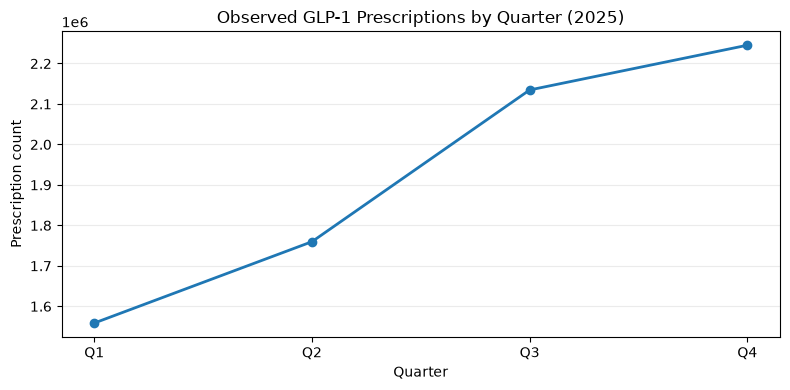

In [49]:
# Install in a separate cell if needed: %pip install matplotlib
import matplotlib.pyplot as plt

quarterly_totals = non_suppressed.groupby(quarter_col)[prescription_col].sum(min_count=1).reindex([1, 2, 3, 4])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(quarterly_totals.index, quarterly_totals.values, marker="o", linewidth=2)
ax.set(title="Observed GLP-1 Prescriptions by Quarter (2025)", xlabel="Quarter", ylabel="Prescription count")
ax.set_xticks([1, 2, 3, 4], ["Q1", "Q2", "Q3", "Q4"])
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

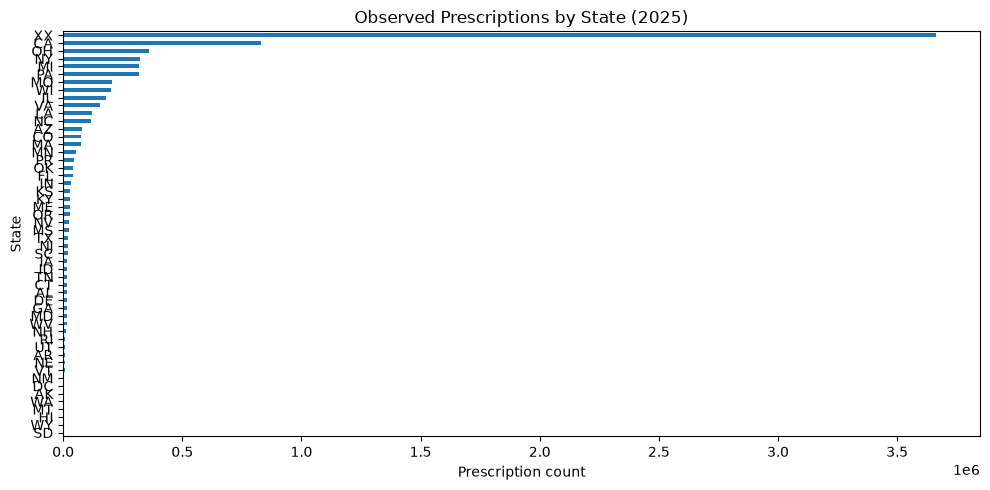

In [50]:
fig, ax = plt.subplots(figsize=(10, 5))
prescriptions_by_state.sort_values().plot(kind="barh", ax=ax)
ax.set(title="Observed Prescriptions by State (2025)", xlabel="Prescription count", ylabel="State")
plt.tight_layout()
plt.show()

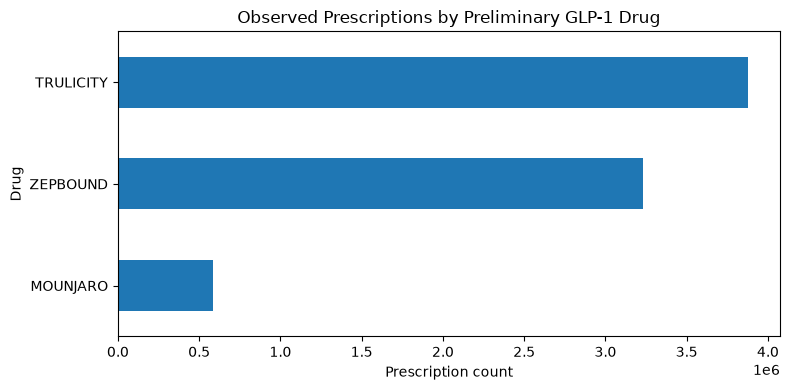

In [51]:
fig, ax = plt.subplots(figsize=(8, 4))
prescriptions_by_drug.sort_values().plot(kind="barh", ax=ax)
ax.set(title="Observed Prescriptions by Preliminary GLP-1 Drug", xlabel="Prescription count", ylabel="Drug")
plt.tight_layout()
plt.show()

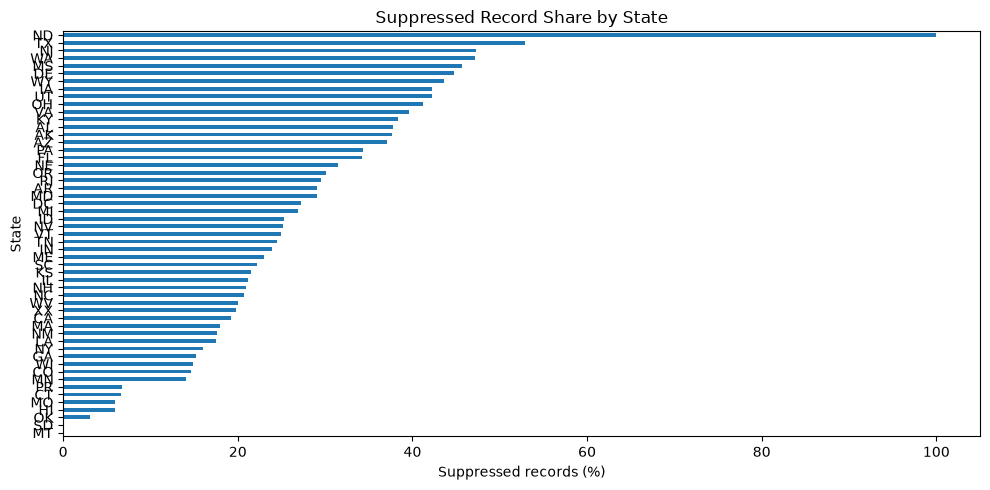

In [52]:
fig, ax = plt.subplots(figsize=(10, 5))
suppression_by_state["Suppression Rate (%)"].sort_values().plot(kind="barh", ax=ax)
ax.set(title="Suppressed Record Share by State", xlabel="Suppressed records (%)", ylabel="State")
plt.tight_layout()
plt.show()

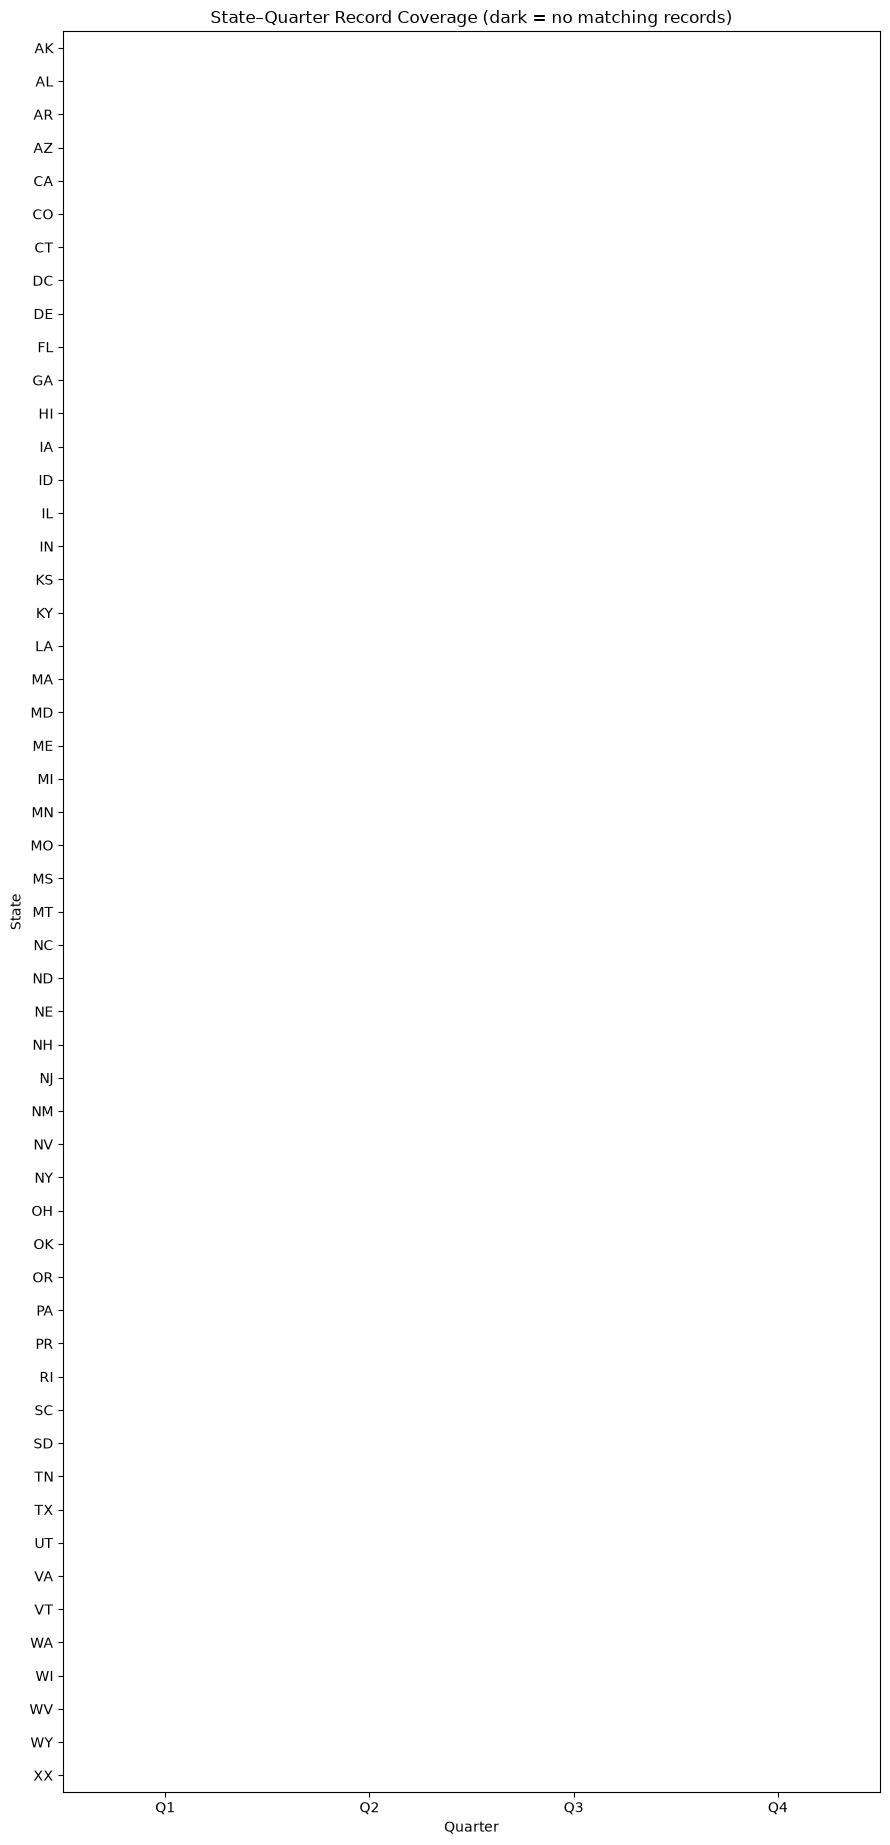

In [53]:
fig, ax = plt.subplots(figsize=(9, max(4, len(coverage)*.35)))
ax.imshow(coverage.eq(0).astype(int).to_numpy(), aspect="auto", cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(4), ["Q1", "Q2", "Q3", "Q4"])
ax.set_yticks(range(len(coverage)), coverage.index.astype(str))
ax.set(title="State–Quarter Record Coverage (dark = no matching records)", xlabel="Quarter", ylabel="State")
plt.tight_layout()
plt.show()

## Step 17 — Final Summary

In [54]:
# ------------------------------------------------------------



print("\n")

print("=" * 60)

print("DATASET 1 — DATA CHECK SUMMARY")

print("=" * 60)



print(

    f"Full dataset rows: "

    f"{len(df):,}"

)



print(

    f"State/Jurisdiction codes in full dataset: "

    f"{df[state_col].nunique()}"

)



print(

    f"GLP-1 records using current preliminary drug list: "

    f"{total_glp1:,}"

)



print(

    f"Suppressed GLP-1 records: "

    f"{suppressed:,}"

)



print(

    f"Suppression rate: "

    f"{suppression_rate:.2f}%"

)



print(

    f"Missing prescription counts among "

    f"non-suppressed records: "

    f"{non_suppressed_missing}"

)



print(

    f"States/jurisdictions with incomplete "

    f"quarter coverage: "

    f"{len(missing_quarter_states)}"

)



print(

    f"Total observable GLP-1 prescriptions "

    f"(non-suppressed records): "

    f"{non_suppressed[prescription_col].sum():,.0f}"

)



print("=" * 60)



DATASET 1 — DATA CHECK SUMMARY
Full dataset rows: 5,308,547
State/Jurisdiction codes in full dataset: 53
GLP-1 records using current preliminary drug list: 3,946
Suppressed GLP-1 records: 1,065
Suppression rate: 26.99%
Missing prescription counts among non-suppressed records: 0
States/jurisdictions with incomplete quarter coverage: 0
Total observable GLP-1 prescriptions (non-suppressed records): 7,698,090
